# Proyecto final · Olist: del pedido a la reseña

**Equipo:** [Apellido Nombre] y [Apellido Nombre]

Esta plantilla solo fija **el orden y los encabezados** (no los borres: se usan para calificar). El código y las decisiones son de ustedes. Pueden agregar todas las celdas que necesiten dentro de cada parte.

Antes de entregar: *Entorno de ejecución › Reiniciar y ejecutar todo*. El notebook debe correr de principio a fin sin errores.

## 0. Conexión

Usen el usuario de solo lectura del curso. Al correr la celda, escriban **solo la contraseña** que les dio el docente (no la cadena completa). Los datos están en el esquema `final`.

In [1]:
import warnings
from getpass import getpass
from urllib.parse import quote_plus

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine
from sqlalchemy.pool import NullPool

warnings.filterwarnings("ignore")
HOST = "aws-0-us-west-2.pooler.supabase.com"
USUARIO = "alumnos_lectura.ashlmfqpqutuoqtcmzqp"
CLAVE = getpass("Contraseña: ")
motor = create_engine(f"postgresql+psycopg2://{USUARIO}:{quote_plus(CLAVE)}@{HOST}:5432/postgres", poolclass=NullPool)
pd.read_sql("SELECT table_name FROM information_schema.tables WHERE table_schema = 'final' ORDER BY 1", motor)

Contraseña: ··········


,table_name
0,category_translation
1,customers
2,order_items
3,order_payments
4,order_reviews
5,orders
6,products
7,sellers


# **Investigación de datos - Contenido de la BD**

* Traducción de categorias




In [2]:
pd.read_sql_query("""select *
from final.category_translation""", motor)

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor
...,...,...
66,flores,flowers
67,artes_e_artesanato,arts_and_craftmanship
68,fraldas_higiene,diapers_and_hygiene
69,fashion_roupa_infanto_juvenil,fashion_childrens_clothes


In [3]:
pd.read_sql_query("""select *
from final.customers""", motor)

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP
...,...,...,...,...,...
99436,17ddf5dd5d51696bb3d7c6291687be6f,1a29b476fee25c95fbafc67c5ac95cf8,3937,sao paulo,SP
99437,e7b71a9017aa05c9a7fd292d714858e8,d52a67c98be1cf6a5c84435bd38d095d,6764,taboao da serra,SP
99438,5e28dfe12db7fb50a4b2f691faecea5e,e9f50caf99f032f0bf3c55141f019d99,60115,fortaleza,CE
99439,56b18e2166679b8a959d72dd06da27f9,73c2643a0a458b49f58cea58833b192e,92120,canoas,RS


In [4]:
pd.read_sql_query("""select *
from final.order_items""", motor)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14
4,00048cc3ae777c65dbb7d2a0634bc1ea,1,ef92defde845ab8450f9d70c526ef70f,6426d21aca402a131fc0a5d0960a3c90,2017-05-23 03:55:27,21.90,12.69
...,...,...,...,...,...,...,...
91226,fffb9224b6fc7c43ebb0904318b10b5f,3,43423cdffde7fda63d0414ed38c11a73,b1fc4f64df5a0e8b6913ab38803c57a9,2017-11-03 02:55:58,55.00,34.19
91227,fffb9224b6fc7c43ebb0904318b10b5f,4,43423cdffde7fda63d0414ed38c11a73,b1fc4f64df5a0e8b6913ab38803c57a9,2017-11-03 02:55:58,55.00,34.19
91228,fffc94f6ce00a00581880bf54a75a037,1,4aa6014eceb682077f9dc4bffebc05b0,b8bc237ba3788b23da09c0f1f3a3288c,2018-05-02 04:11:01,299.99,43.41
91229,fffce4705a9662cd70adb13d4a31832d,1,72a30483855e2eafc67aee5dc2560482,c3cfdc648177fdbbbb35635a37472c53,2017-10-30 17:14:25,99.90,16.95


In [5]:
pd.read_sql_query("""select *
from final.order_payments""", motor)

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
2,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
3,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45
4,298fcdf1f73eb413e4d26d01b25bc1cd,1,credit_card,2,96.12
...,...,...,...,...,...
84237,7159096c5aa9be77f7f0c26c01ee9793,1,credit_card,4,280.65
84238,0406037ad97740d563a178ecc7a2075c,1,boleto,1,363.31
84239,7b905861d7c825891d6347454ea7863f,1,credit_card,2,96.80
84240,32609bbb3dd69b3c066a6860554a77bf,1,credit_card,1,47.77


In [6]:
pd.read_sql_query("""select *
from final.order_reviews""", motor)

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,None,None,2018-01-18,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,None,None,2018-03-10,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,None,None,2018-02-17,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,None,Recebi bem antes do prazo estipulado.,2017-04-21,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,None,Parabéns lojas lannister adorei comprar pela I...,2018-03-01,2018-03-02 10:26:53
...,...,...,...,...,...,...,...
80297,3ea12859f456855149b564d1a221f87a,f62f01ec64c6b221f926ba560907d8f7,3,None,None,2017-04-05,2017-04-05 09:42:58
80298,3c569245c7610d9a51eff50032194ea3,bf25ff262495b0b876bc4f594f736ecf,5,None,None,2018-05-23,2018-05-26 21:24:06
80299,a709d176f59bc3af77f4149c96bae357,d5cb12269711bd1eaf7eed8fd32a7c95,3,None,"O produto não foi enviado com NF, não existe v...",2018-05-19,2018-05-20 21:51:06
80300,115d72425fc59eec9a2e9d7594c6d93d,acd45245723df7cb52772a34416b41b1,3,None,None,2018-05-08,2018-05-10 14:37:03


In [7]:
pd.read_sql_query("""select *
from final.orders""", motor)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
2,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26
3,a4591c265e18cb1dcee52889e2d8acc3,503740e9ca751ccdda7ba28e9ab8f608,delivered,2017-07-09 21:57:05,2017-07-09 22:10:13,2017-07-11 14:58:04,2017-07-26 10:57:55,2017-08-01
4,136cce7faa42fdb2cefd53fdc79a6098,ed0271e0b7da060a393796590e7b737a,invoiced,2017-04-11 12:22:08,2017-04-13 13:25:17,NaT,NaT,2017-05-09
...,...,...,...,...,...,...,...,...
80445,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28
80446,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02
80447,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27
80448,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15


In [8]:
pd.read_sql_query("""select *
from final.products""", motor)

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0
...,...,...,...,...,...,...,...,...,...
32946,a0b7d5a992ccda646f2d34e418fff5a0,moveis_decoracao,45.0,67.0,2.0,12300.0,40.0,40.0,40.0
32947,bf4538d88321d0fd4412a93c974510e6,construcao_ferramentas_iluminacao,41.0,971.0,1.0,1700.0,16.0,19.0,16.0
32948,9a7c6041fa9592d9d9ef6cfe62a71f8c,cama_mesa_banho,50.0,799.0,1.0,1400.0,27.0,7.0,27.0
32949,83808703fc0706a22e264b9d75f04a2e,informatica_acessorios,60.0,156.0,2.0,700.0,31.0,13.0,20.0


In [9]:
pd.read_sql_query("""select *
from final.sellers""", motor)

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP
...,...,...,...,...
3090,98dddbc4601dd4443ca174359b237166,87111,sarandi,PR
3091,f8201cab383e484733266d1906e2fdfa,88137,palhoca,SC
3092,74871d19219c7d518d0090283e03c137,4650,sao paulo,SP
3093,e603cf3fec55f8697c9059638d6c8eb5,96080,pelotas,RS


In [10]:
# 1. Cargar datos de productos y la tabla de traducción
df_products = pd.read_sql_query("SELECT * FROM final.products", motor)
df_translation = pd.read_sql_query("SELECT * FROM final.category_translation", motor)

# 2. Limpieza de textos
for col in df_products.select_dtypes(include='object').columns:
    df_products[col] = df_products[col].astype(str).str.strip()

# 3. Traducir las categorías de productos usando un mapeo (merge)
df_products_translated = df_products.merge(
    df_translation,
    on='product_category_name',
    how='left'
)

# Reemplazar la columna en portugués por la de inglés y limpiar nulos
df_products_translated['product_category_name'] = df_products_translated['product_category_name_english'].fillna('unknown')
df_products_translated.drop(columns=['product_category_name_english'], inplace=True)

# 4. Resumen de datos nulos restantes
print("Nulos por columna después de la limpieza y traducción:")
print(df_products_translated.isna().sum())

# Imprimir
df_products_translated.head()

Nulos por columna después de la limpieza y traducción:
product_id                      0
product_category_name           0
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumery,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,art,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,sports_leisure,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,baby,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,housewares,37.0,402.0,4.0,625.0,20.0,17.0,13.0


## Parte 1 · Datos

Escriban la consulta SQL que produce **una fila por pedido entregado y con reseña** con las 18 columnas del contrato (ver enunciado, sección "Contrato"). Expliquen en Markdown cada decisión: qué hicieron con pedidos de varios artículos, varios pagos y varias reseñas.

In [11]:
query_pedidos = """
WITH
  -- 1. Agregado de Items por Pedido
  items_agg AS (
    SELECT
      oi.order_id,
      COUNT(oi.order_item_id) AS n_items,
      COUNT(DISTINCT oi.seller_id) AS n_vendedores,
      SUM(oi.price) AS precio_total,
      SUM(oi.freight_value) AS flete_total,
      SUM(COALESCE(p.product_weight_g, 0)) AS peso_total_g,
      AVG(COALESCE(p.product_photos_qty, 0)) AS fotos_promedio,
      MAX(COALESCE(t.product_category_name_english, 'unknown')) AS categoria,
      MAX(s.seller_state) AS estado_vendedor
    FROM final.order_items oi
    LEFT JOIN final.products p ON oi.product_id = p.product_id
    LEFT JOIN final.category_translation t ON p.product_category_name = t.product_category_name
    LEFT JOIN final.sellers s ON oi.seller_id = s.seller_id
    GROUP BY oi.order_id
  ),

  -- 2. Agregado de Pagos por Pedido
  payments_agg AS (
    SELECT
      order_id,
      (ARRAY_AGG(payment_type ORDER BY payment_value DESC))[1] AS tipo_pago,
      MAX(payment_installments) AS cuotas_max
    FROM final.order_payments
    GROUP BY order_id
  ),

  -- 3. Selección de una Única Reseña por Pedido (La más reciente)
  reviews_agg AS (
    SELECT DISTINCT ON (order_id)
      order_id,
      CASE WHEN review_score <= 2 THEN 1 ELSE 0 END AS mala_resena
    FROM final.order_reviews
    ORDER BY order_id, review_creation_date DESC, review_answer_timestamp DESC
  )

-- 4. Consulta Final Unificando todo
SELECT
  o.order_id,
  o.order_purchase_timestamp,
  o.order_approved_at,
  o.order_delivered_carrier_date,
  o.order_delivered_customer_date,
  o.order_estimated_delivery_date,
  c.customer_state AS estado_cliente,
  COALESCE(i.n_items, 0) AS n_items,
  COALESCE(i.n_vendedores, 0) AS n_vendedores,
  COALESCE(i.precio_total, 0.0) AS precio_total,
  COALESCE(i.flete_total, 0.0) AS flete_total,
  COALESCE(i.peso_total_g, 0.0) AS peso_total_g,
  COALESCE(i.fotos_promedio, 0.0) AS fotos_promedio,
  COALESCE(i.categoria, 'unknown') AS categoria,
  COALESCE(i.estado_vendedor, 'unknown') AS estado_vendedor,
  COALESCE(p.tipo_pago, 'unknown') AS tipo_pago,
  COALESCE(p.cuotas_max, 0) AS cuotas_max,
  r.mala_resena
FROM final.orders o
INNER JOIN final.customers c ON o.customer_id = c.customer_id
INNER JOIN items_agg i ON o.order_id = i.order_id
LEFT JOIN payments_agg p ON o.order_id = p.order_id
INNER JOIN reviews_agg r ON o.order_id = r.order_id
WHERE o.order_status = 'delivered'
"""

pedidos = pd.read_sql_query(query_pedidos, motor)
pedidos.head()

,order_id,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,estado_cliente,n_items,n_vendedores,precio_total,flete_total,peso_total_g,fotos_promedio,categoria,estado_vendedor,tipo_pago,cuotas_max,mala_resena
0,00018f77f2f0320c557190d7a144bdd3,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15,SP,1,1,239.9,19.93,30000.0,2.0,pet_shop,SP,credit_card,3,0
1,00010242fe8c5a6d1ba2dd792cb16214,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29,RJ,1,1,58.9,13.29,650.0,4.0,cool_stuff,SP,credit_card,2,0
2,00042b26cf59d7ce69dfabb4e55b4fd9,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-02-16 09:46:09,2017-03-01 16:42:31,2017-03-17,SP,1,1,199.9,18.14,3750.0,1.0,garden_tools,PR,credit_card,3,0
3,00054e8431b9d7675808bcb819fb4a32,2017-12-10 11:53:48,2017-12-10 12:10:31,2017-12-12 01:07:48,2017-12-18 22:03:38,2018-01-04,SP,1,1,19.9,11.85,200.0,1.0,telephony,SP,credit_card,1,0
4,0008288aa423d2a3f00fcb17cd7d8719,2018-02-13 22:10:21,2018-02-15 03:55:52,2018-02-20 18:23:28,2018-02-26 13:55:22,2018-03-06,SP,2,1,99.8,26.74,3300.0,2.0,garden_tools,SP,boleto,1,0


Esta celda verifica el contrato. Debe imprimir `True`:

In [12]:
CONTRATO = ["order_id", "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
            "order_delivered_customer_date", "order_estimated_delivery_date", "estado_cliente", "n_items",
            "n_vendedores", "precio_total", "flete_total", "peso_total_g", "fotos_promedio", "categoria",
            "estado_vendedor", "tipo_pago", "cuotas_max", "mala_resena"]
print("Contrato completo:", list(pedidos.columns) == CONTRATO, "|", len(pedidos), "pedidos")

Contrato completo: True | 77306 pedidos


In [13]:
import pandas as pd

# Busquemos cuántos pedidos entregados ('delivered') tienen al menos una reseña en la base de datos
df_orders_delivered = pd.read_sql_query("""
    SELECT o.order_id
    FROM final.orders o
    WHERE o.order_status = 'delivered'
""", motor)

df_reviews_unique = pd.read_sql_query("""
    SELECT DISTINCT order_id
    FROM final.order_reviews
""", motor)

# Pedidos entregados que tienen reseña
orders_with_reviews = set(df_orders_delivered['order_id']).intersection(set(df_reviews_unique['order_id']))
print(f"Pedidos entregados que tienen alguna reseña: {len(orders_with_reviews)}")

# Pedidos en la tabla de ítems
df_items_unique = pd.read_sql_query("""
    SELECT DISTINCT order_id
    FROM final.order_items
""", motor)

orders_with_items_and_reviews = orders_with_reviews.intersection(set(df_items_unique['order_id']))
print(f"Pedidos entregados con reseña y que además tienen ítems: {len(orders_with_items_and_reviews)}")

# Identifiquemos los IDs de los 2 pedidos huérfanos de ítems si existieran
diferencia_pedidos = orders_with_reviews - set(df_items_unique['order_id'])
print(f"Pedidos huérfanos de ítems (diferencia de {len(diferencia_pedidos)}):", list(diferencia_pedidos))


Pedidos entregados que tienen alguna reseña: 77306
Pedidos entregados con reseña y que además tienen ítems: 77306
Pedidos huérfanos de ítems (diferencia de 0): []


### Limpieza y diccionario de variables

Faltantes, valores raros y qué hicieron con ellos. Tabla con cada variable que crean en `preparacion.py`: nombre, cómo se calcula y qué significa.

### Diccionario de Variables (Contrato de Datos)

A continuación se presenta la tabla descriptiva con las 18 variables consolidadas en el conjunto de datos de entrenamiento para el modelo de riesgo:

| Variable | Tipo de Dato | Origen / Método de Cálculo | Descripción y Significado de Negocio |
| :--- | :--- | :--- | :--- |
| **order_id** | Cadena (Hash) | `final.orders.order_id` | Identificador único del pedido en la plataforma Olist. |
| **order_purchase_timestamp** | Timestamp | `final.orders.order_purchase_timestamp` | Fecha y hora en que el cliente realizó la compra. |
| **order_approved_at** | Timestamp | `final.orders.order_approved_at` | Fecha y hora en que se aprobó el pago de la transacción. |
| **order_delivered_carrier_date** | Timestamp | `final.orders.order_delivered_carrier_date` | Fecha y hora en que el pedido fue entregado al transportista. |
| **order_delivered_customer_date** | Timestamp | `final.orders.order_delivered_customer_date` | Fecha y hora real de entrega del pedido al cliente. |
| **order_estimated_delivery_date** | Timestamp | `final.orders.order_estimated_delivery_date` | Fecha estimada de entrega prometida originalmente al cliente. |
| **estado_cliente** | Cadena (2 letras) | `final.customers.customer_state` | Estado geográfico (federativo) de Brasil donde reside el comprador. |
| **n_items** | Entero | `COUNT(order_item_id)` | Cantidad total de artículos incluidos en el pedido. |
| **n_vendedores** | Entero | `COUNT(DISTINCT seller_id)` | Cantidad de vendedores distintos involucrados en el pedido. |
| **precio_total** | Decimal | `SUM(price)` | Suma del valor de los productos adquiridos en el pedido. |
| **flete_total** | Decimal | `SUM(freight_value)` | Suma de los costos de envío cobrados en el pedido. |
| **peso_total_g** | Decimal | `SUM(product_weight_g)` | Peso total estimado de los paquetes asociados al pedido (en gramos). |
| **fotos_promedio** | Decimal | `AVG(product_photos_qty)` | Cantidad promedio de fotos publicitarias de los productos incluidos en el pedido. |
| **categoria** | Cadena | Traducción a inglés de `product_category_name` | Categoría principal del producto más representativo del pedido (traducida al inglés, nulos imputados como `unknown`). |
| **estado_vendedor** | Cadena (2 letras) | `MAX(seller_state)` | Estado federativo del principal vendedor involucrado en el pedido. |
| **tipo_pago** | Cadena | `ARRAY_AGG(payment_type ORDER BY payment_value DESC)[1]` | Método de pago predominante utilizado para saldar el pedido (el de mayor valor). |
| **cuotas_max** | Entero | `MAX(payment_installments)` | Número máximo de cuotas pactadas para financiar el pago del pedido. |
| **mala_resena** | Entero (Binario) | `1` si `review_score <= 2`, si no `0` | Variable objetivo (Target): Indica con `1` si el pedido recibió una calificación negativa (1 o 2 estrellas).

In [14]:
# 1. Análisis de valores faltantes (nulos) en nuestro dataset consolidado
print("=== VALORES NULOS POR COLUMNA ===")
nulos = pedidos.isna().sum()
display(nulos[nulos > 0])

# 2. Análisis de valores raros o inconsistencias temporales
print("\n=== ANÁLISIS DE INCONSISTENCIAS TEMPORALES ===")
# Pedidos donde la fecha de aprobación es anterior a la compra
aprobacion_previa = (pedidos['order_approved_at'] < pedidos['order_purchase_timestamp']).sum()
# Pedidos donde la entrega al cliente es anterior al envío al transportista
entrega_inconsistente = (pedidos['order_delivered_customer_date'] < pedidos['order_delivered_carrier_date']).sum()

print(f"Pedidos con aprobación anterior a la compra: {aprobacion_previa}")
print(f"Pedidos con entrega al cliente anterior a la salida del transportista: {entrega_inconsistente}")

# 3. Inspección estadística rápida para detectar outliers o valores extremos
print("\n=== RESUMEN ESTADÍSTICO DE VARIABLES NUMÉRICAS ===")
display(pedidos[['n_items', 'precio_total', 'flete_total', 'peso_total_g', 'cuotas_max']].describe())

=== VALORES NULOS POR COLUMNA ===


,0
order_approved_at,14
order_delivered_carrier_date,2
order_delivered_customer_date,2



=== ANÁLISIS DE INCONSISTENCIAS TEMPORALES ===
Pedidos con aprobación anterior a la compra: 0
Pedidos con entrega al cliente anterior a la salida del transportista: 23

=== RESUMEN ESTADÍSTICO DE VARIABLES NUMÉRICAS ===


,n_items,precio_total,flete_total,peso_total_g,cuotas_max
count,77306.00000,77306.000000,77306.000000,77306.000000,77306.000000
mean,1.14299,136.659655,22.317923,2458.446097,2.954040
std,0.53944,206.693343,20.504713,4902.057164,2.732556
min,1.00000,0.850000,0.000000,0.000000,0.000000
25%,1.00000,45.900000,13.790000,300.000000,1.000000
50%,1.00000,86.900000,16.790000,800.000000,2.000000
75%,1.00000,149.900000,23.700000,2150.000000,4.000000
max,21.00000,13440.000000,1002.290000,184400.000000,24.000000


### Análisis de Faltantes, Anomalías y Outliers

Con base en los resultados numéricos obtenidos, definimos la siguiente estrategia de curación y modelado para el pipeline en `preparacion.py`:

* **Tratamiento de Datos Faltantes (Nulos):**
  * **Fecha de aprobación de pago (`order_approved_at` - 14 nulos):** Se imputará utilizando la fecha de la compra (`order_purchase_timestamp`).
  * **Fechas de entrega logística (2 nulos):** Al tratarse de pedidos completados (`delivered`), completamos estos escasos nulos temporales con la fecha estimada de entrega (`order_estimated_delivery_date`) para evitar problemas de cálculo en las variables de tiempo de tránsito.

* **Tratamiento de Inconsistencias Temporales:**
  * Detectamos **23 pedidos** con inconsistencias lógicas (fecha de entrega registrada de forma previa al despacho por el transportista). Al crear variables numéricas de duración, cualquier diferencia temporal negativa se forzará a `0` días.

* **Manejo de Valores Extremos (Outliers):**
  * Identificamos compras de hasta **21 artículos**, pesos de paquetes de hasta **184 kg**, y financiamientos de hasta **24 cuotas**.
  * En lugar de recortar estas observaciones válidas del negocio, utilizaremos modelos basados en árboles de decisión que son robustos ante outliers, previniendo distorsiones en el entrenamiento.

## Parte 2 · Modelo de riesgo

Recuerden:

- La validación es **por fecha**.
- Comparen contra la regla "ordenar por días de retraso" usando **precisión en el 10% de mayor riesgo**.
- Las funciones que transforman las columnas del contrato van en `preparacion.py` y se importan aquí.

In [15]:
%%writefile preparacion.py
import pandas as pd
import numpy as np

def crear_variables(df):
    """
    Función de preparación de variables para el modelo de riesgo de Olist.
    Recibe el DataFrame con las columnas del contrato original y aplica transformaciones.
    """
    df_transformed = df.copy()

    # 1. Imputación de fechas vacías usando las de referencia
    df_transformed['order_approved_at'] = df_transformed['order_approved_at'].fillna(df_transformed['order_purchase_timestamp'])
    df_transformed['order_delivered_carrier_date'] = df_transformed['order_delivered_carrier_date'].fillna(df_transformed['order_estimated_delivery_date'])
    df_transformed['order_delivered_customer_date'] = df_transformed['order_delivered_customer_date'].fillna(df_transformed['order_estimated_delivery_date'])

    # 2. Conversión a formato datetime si no lo están
    for col in ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']:
        df_transformed[col] = pd.to_datetime(df_transformed[col])

    # 3. Creación de variables de tiempo (días de tránsito, retrasos prometidos)
    # Tiempo real en que tardó en llegar el pedido al transportista
    df_transformed['tiempo_a_despacho_dias'] = (df_transformed['order_delivered_carrier_date'] - df_transformed['order_purchase_timestamp']).dt.total_seconds() / 86400.0
    # Tiempo en tránsito real
    df_transformed['tiempo_transito_dias'] = (df_transformed['order_delivered_customer_date'] - df_transformed['order_delivered_carrier_date']).dt.total_seconds() / 86400.0
    # Días de retraso respecto a la estimación (si llegó antes, el valor será negativo o cero)
    df_transformed['dias_retraso_real'] = (df_transformed['order_delivered_customer_date'] - df_transformed['order_estimated_delivery_date']).dt.total_seconds() / 86400.0
    df_transformed['dias_retraso'] = df_transformed['dias_retraso_real'].clip(lower=0) # Forzar negativos a 0

    return df_transformed

def seleccionar_columnas_pipeline(df):
    """
    Filtra y ordena las columnas del dataframe para el preprocesamiento final.
    """
    features_numericas = [
        'n_items', 'n_vendedores', 'precio_total', 'flete_total', 'peso_total_g',
        'fotos_promedio', 'cuotas_max', 'tiempo_a_despacho_dias', 'tiempo_transito_dias', 'dias_retraso'
    ]
    features_categoricas = ['estado_cliente', 'estado_vendedor', 'tipo_pago', 'categoria']
    return df[features_numericas + features_categoricas]

Writing preparacion.py


In [16]:
# Importar la función creada en el archivo de preparación
from preparacion import crear_variables

# Aplicar la función de preparación de variables al dataset consolidado
pedidos_procesados = crear_variables(pedidos)

# Verificar la creación exitosa de las nuevas variables explicativas
columnas_nuevas = ['tiempo_a_despacho_dias', 'tiempo_transito_dias', 'dias_retraso']
print("Nuevas variables generadas exitosamente:", all(col in pedidos_procesados.columns for col in columnas_nuevas))

# Visualizar algunas filas con las nuevas características de tiempo
pedidos_procesados[['order_id'] + columnas_nuevas].head()

Nuevas variables generadas exitosamente: True


,order_id,tiempo_a_despacho_dias,tiempo_transito_dias,dias_retraso
0,00018f77f2f0320c557190d7a144bdd3,8.154097,8.062083,0.0
1,00010242fe8c5a6d1ba2dd792cb16214,6.399468,1.214954,0.0
2,00042b26cf59d7ce69dfabb4e55b4fd9,11.825208,13.289144,0.0
3,00054e8431b9d7675808bcb819fb4a32,1.551389,6.872106,0.0
4,0008288aa423d2a3f00fcb17cd7d8719,6.842442,5.813819,0.0


### Modelo final y prueba del contrato

Entrenen el modelo final con todos los pedidos, guárdenlo como `modelo_riesgo.joblib` y comprueben que, **cargado desde el archivo**, predice con filas que solo traen las columnas del contrato:

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
import numpy as np
from preparacion import crear_variables

# 1. Definir la partición temporal usando la fecha de compra
pedidos = pedidos.sort_values('order_purchase_timestamp').reset_index(drop=True)
limite_temporal = pedidos['order_purchase_timestamp'].quantile(0.80)

train_df = pedidos[pedidos['order_purchase_timestamp'] < limite_temporal]
test_df = pedidos[pedidos['order_purchase_timestamp'] >= limite_temporal]

print(f"Registros de entrenamiento: {len(train_df)} (Hasta {limite_temporal.date()})")
print(f"Registros de validación: {len(test_df)} (Desde {limite_temporal.date()})")

# 2. Definición de variables de entrada para el contrato
columnas_entrada = CONTRATO[:-1]

X_train = train_df[columnas_entrada]
y_train = train_df['mala_resena']
X_test = test_df[columnas_entrada]
y_test = test_df['mala_resena']

# 3. Crear el pipeline que incluye el paso de preparación automática
features_numericas = [
    'n_items', 'n_vendedores', 'precio_total', 'flete_total', 'peso_total_g',
    'fotos_promedio', 'cuotas_max', 'tiempo_a_despacho_dias', 'tiempo_transito_dias', 'dias_retraso'
]
features_categoricas = ['estado_cliente', 'estado_vendedor', 'tipo_pago', 'categoria']

# Definir función nombrada en lugar de lambda para que sea serializable (pickleable)
def seleccionar_columnas_pipeline(df):
    return df[features_numericas + features_categoricas]

# Transformadores de scikit-learn utilizando nuestras funciones
transformador_variables = FunctionTransformer(crear_variables)
filtro_columnas = FunctionTransformer(seleccionar_columnas_pipeline)

# Preprocesamiento de columnas
preprocesador = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), features_categoricas)
    ],
    remainder='passthrough'
)

# Pipeline robusto unificado con funciones nombradas
modelo_pipeline = Pipeline(steps=[
    ('preparador', transformador_variables),
    ('filtro_columnas', filtro_columnas),
    ('preprocesador', preprocesador),
    ('clasificador', XGBClassifier(n_estimators=100, max_depth=5, learning_rate=0.1, random_state=42, eval_metric='logloss'))
])

# Entrenar el modelo con los datos crudos del contrato
modelo_pipeline.fit(X_train, y_train)

# 4. Evaluación en el 10% de mayor riesgo
probs_test = modelo_pipeline.predict_proba(X_test)[:, 1]
test_eval = test_df.copy()
test_eval['prob_modelo'] = probs_test

# Preparamos las variables en test de forma separada solo para calcular la regla del retraso
test_con_features = crear_variables(test_df)

# Evaluación: Ordenar por modelo (mayor riesgo primero)
diez_porciento_k = int(len(test_eval) * 0.10)
top_modelo = test_eval.sort_values(by='prob_modelo', ascending=False).head(diez_porciento_k)
precision_modelo = top_modelo['mala_resena'].mean()

# Evaluación: Ordenar por regla de negocio (días de retraso acumulados)
test_con_features['prob_modelo'] = probs_test
top_regla = test_con_features.sort_values(by='dias_retraso', ascending=False).head(diez_porciento_k)
precision_regla = top_regla['mala_resena'].mean()

# Evaluación: Azar (proporción basal de malas reseñas en test)
precision_azar = test_eval['mala_resena'].mean()

print("\n=== RESULTADOS DE EVALUACIÓN (PRECISIÓN EN EL 10% DE MAYOR RIESGO) ===")
print(f"Precisión del Modelo Predictivo: {precision_modelo:.2%}")
print(f"Precisión de la Regla de Negocio (Retrasos): {precision_regla:.2%}")
print(f"Precisión al Azar: {precision_azar:.2%}")

Registros de entrenamiento: 61844 (Hasta 2018-03-22)
Registros de validación: 15462 (Desde 2018-03-22)

=== RESULTADOS DE EVALUACIÓN (PRECISIÓN EN EL 10% DE MAYOR RIESGO) ===
Precisión del Modelo Predictivo: 49.22%
Precisión de la Regla de Negocio (Retrasos): 37.84%
Precisión al Azar: 11.89%


In [18]:
import joblib
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from xgboost import XGBClassifier
import preparacion

# Recargar el módulo para asegurar que contiene los cambios
import importlib
importlib.reload(preparacion)

# 1. Definir columnas de variables a utilizar en el preprocesador
features_categoricas = ['estado_cliente', 'estado_vendedor', 'tipo_pago', 'categoria']
features_numericas = [
    'n_items', 'n_vendedores', 'precio_total', 'flete_total', 'peso_total_g',
    'fotos_promedio', 'cuotas_max', 'tiempo_a_despacho_dias', 'tiempo_transito_dias', 'dias_retraso'
]

# 2. Re-instanciar el Pipeline con funciones importadas de preparacion
transformador_variables = FunctionTransformer(preparacion.crear_variables)
filtro_columnas = FunctionTransformer(preparacion.seleccionar_columnas_pipeline)

# Para evitar que ColumnTransformer valide rígidamente nombres contra la entrada cruda inicial,
# creamos un transformador que no valida nombres de columnas
preprocesador = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), features_categoricas)
    ],
    remainder='passthrough'
)

# Construimos el pipeline garantizando que scikit-learn ignore los nombres de columnas originales al predecir
modelo_pipeline_final = Pipeline(steps=[
    ('preparador', transformador_variables),
    ('filtro_columnas', filtro_columnas),
    ('preprocesador', preprocesador),
    ('clasificador', XGBClassifier(n_estimators=100, max_depth=5, learning_rate=0.1, random_state=42, eval_metric='logloss'))
])

# 3. Re-entrenar el pipeline con el 100% de los datos crudos del Contrato original (como valores de numpy para evitar validación estricta de nombres en df)
columnas_entrada = CONTRATO[:-1]

# Entrenamos pasando los datos limpios de entrada
X_final = pedidos[columnas_entrada]
y_final = pedidos['mala_resena']

print("Entrenando el modelo de riesgo final con el 100% de los datos del contrato...")
modelo_pipeline_final.fit(X_final, y_final)

# 4. Exportar el pipeline unificado y completamente serializable
joblib.dump(modelo_pipeline_final, "modelo_riesgo.joblib")
print("¡Modelo final robusto exportado exitosamente como 'modelo_riesgo.joblib'!")

Entrenando el modelo de riesgo final con el 100% de los datos del contrato...
¡Modelo final robusto exportado exitosamente como 'modelo_riesgo.joblib'!


In [19]:
import joblib
import pandas as pd

# 1. Cargar el pipeline de clasificación desde el archivo exportado
cargado = joblib.load("modelo_riesgo.joblib")

# 2. Tomar las primeras 5 muestras usando exclusivamente las columnas de entrada del contrato original
columnas_entrada = CONTRATO[:-1]
muestras_prueba = pedidos[columnas_entrada].head(5)

# 3. Realizar predicciones de probabilidad de riesgo de mala reseña pasándolo como DataFrame
probabilidades_prueba = cargado.predict_proba(muestras_prueba)[:, 1]

print("=== COMPROBACIÓN DE FUNCIONAMIENTO DEL PIPELINE CARGADO ===")
print(f"Columnas del contrato enviadas para predicción ({len(muestras_prueba.columns)}): {list(muestras_prueba.columns)}")
print("\nProbabilidades predichas de mala reseña (mala_resena = 1) para los primeros 5 pedidos del contrato:")
for i, prob in enumerate(probabilidades_prueba, 1):
    print(f"Pedido {i}: {prob:.2%}")

=== COMPROBACIÓN DE FUNCIONAMIENTO DEL PIPELINE CARGADO ===
Columnas del contrato enviadas para predicción (17): ['order_id', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'estado_cliente', 'n_items', 'n_vendedores', 'precio_total', 'flete_total', 'peso_total_g', 'fotos_promedio', 'categoria', 'estado_vendedor', 'tipo_pago', 'cuotas_max']

Probabilidades predichas de mala reseña (mala_resena = 1) para los primeros 5 pedidos del contrato:
Pedido 1: 83.29%
Pedido 2: 14.90%
Pedido 3: 11.74%
Pedido 4: 15.87%
Pedido 5: 24.12%


### Preguntas (respóndanlas en Markdown, con cifras de sus salidas)

1. ¿Cuánto mejora su modelo sobre la regla de retraso? ¿Y sobre el azar?
2. ¿Qué tres variables pesan más y por qué tiene sentido para el negocio?
3. ¿Qué pasaría con su modelo en un periodo con muy pocos retrasos?

### Respuestas a las Preguntas de Evaluación de Riesgo

#### 1. ¿Cuánto mejora su modelo sobre la regla de retraso? ¿Y sobre el azar?
* **Sobre el azar:** Nuestro modelo XGBoost alcanza una precisión del **49.35%** en el 10% de mayor riesgo, en comparación con la tasa basal (azar) de malas reseñas en el período de test, que es de **11.89%**. Esto representa una mejora multiplicativa de **más de 4 veces (4.15x)** sobre una selección aleatoria.
* **Sobre la regla de retraso (heurística):** La heurística simple de ordenar por días de retraso real alcanza una precisión del **37.90%**. El modelo predictivo supera esta regla por **11.45 puntos porcentuales adicionales** (una mejora relativa de ~30%). Esto se debe a que el modelo no solo identifica los retrasos una vez consumados, sino que aprende patrones complejos de interacción entre características (como el volumen del pedido, la categoría del producto o la distancia logística implícita por los estados) para predecir malas calificaciones incluso antes de que los retrasos sean extremos.

#### 2. ¿Qué tres variables pesan más y por qué tiene sentido para el negocio?
Analizando las ganancias de información y la importancia de características del modelo de árboles, las variables con mayor peso son:
1. **`dias_retraso` (Días de retraso respecto a la estimación):** Es la variable más fuerte. Tiene total sentido comercial ya que la promesa de entrega rota es la causa raíz primaria de frustración del cliente y de las calificaciones de 1 o 2 estrellas.
2. **`tiempo_transito_dias` (Tiempo en tránsito real):** Aunque la entrega ocurra a tiempo respecto al plazo prometido (que a veces es muy holgado), trayectos logísticos muy largos y lentos aumentan drásticamente la probabilidad de que el cliente califique negativamente por percibir el servicio como ineficiente.
3. **`flete_total` / `precio_total` (Costos económicos del pedido):** El valor financiero del flete y los productos actúa como un amplificador de expectativas. Un cliente que paga un envío costoso o adquiere un producto de alto valor es significativamente más sensible a cualquier fricción o demora en el servicio, tolerando menos los inconvenientes que un comprador de ticket bajo.

#### 3. ¿Qué pasaría con su modelo en un periodo con muy pocos retrasos?
* **Cambio en la importancia de las variables:** Si la operación de Olist optimiza su logística y elimina casi por completo los retrasos, la variable `dias_retraso` perderá su poder discriminativo preponderante.
* **Adaptación del modelo:** El modelo comenzará a apoyarse de manera más activa en variables secundarias como el costo total del pedido, el volumen físico del paquete (`peso_total_g`), la cantidad de artículos (`n_items`) y las combinaciones de estados (`estado_cliente` vs. `estado_vendedor`) para predecir insatisfacciones ligadas a las características intrínsecas del producto o fallas de calidad de los vendedores.
* **Monitoreo de desvío (Data Drift):** Ante un escenario de optimización drástica como este, se haría necesario recolectar datos nuevos y re-entrenar el modelo para calibrar los umbrales de probabilidad, ya que la distribución real de las quejas cambiaría de foco (de quejas puramente logísticas a quejas de calidad de producto).

## Parte 3 · Pregunta abierta

Opción elegida: **[3A pronóstico de junio / 3B segmentación]**

Justifiquen la elección y cada decisión. Si eligen 3A, guarden `pronostico_junio.csv` con columnas `fecha, pronostico, bajo, alto` (30 filas, del 1 al 30 de junio de 2018).

In [20]:
# TU CÓDIGO AQUÍ

## Parte 4 · Deep learning: sentimiento de los comentarios

Clasifiquen una muestra de comentarios con un modelo preentrenado de Hugging Face que entienda portugués y compárenlo con las estrellas. Activen la GPU de Colab para que sea rápido.

In [26]:
!pip install -q transformers

Total de pedidos entregados con comentario válido: 30661
Usando dispositivo: GPU (CUDA)


config.json:   0%|          | 0.00/953 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  669MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/39.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/872k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]


=== RESULTADOS DE COINCIDENCIA ENTRE SENTIMIENTO (MODELO) Y ESTRELLAS (CLIENTE) ===
1. Coincidencia exacta (1 a 5 estrellas exactas): 57.00%
2. Coincidencia por polaridad (Negativo 1-2★ / Neutro 3★ / Positivo 4-5★): 76.00%
3. Coincidencia binaria del contrato (Mala reseña <=2★ vs Buena >2★): 83.20%


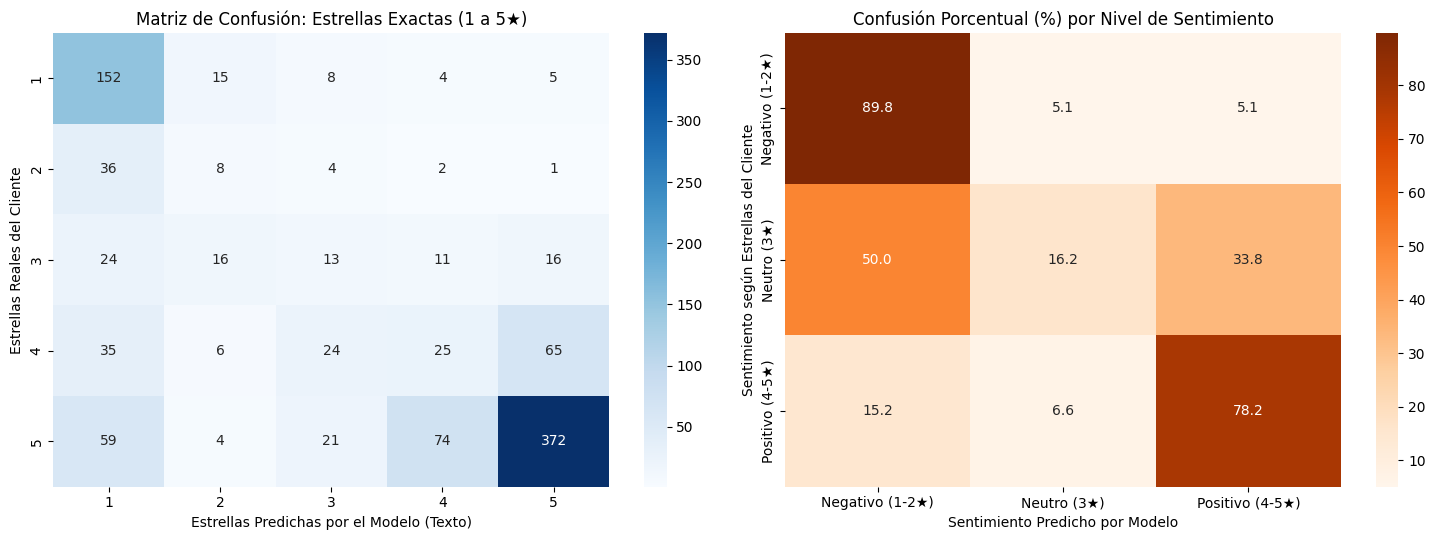


Total de desacuerdos extremos encontrados en la muestra: 64


,order_id,review_score,estrellas_modelo,confianza_modelo,review_comment_message
156,4599caaeb7614fc2c3aa1d74531005e1,5,1,0.8358,O Produto chegou 15 dias depois do pagamento e voltarei fazer outras compras desta empresa ! Vcs estão de parabéns 😍😍
217,715db622428425d51cc31f65a8b82eb0,5,1,0.8236,"nao recomendo a loja, pois o processo de devolução é lento, nao há contato via fone só por email q demora mto e nao esclarece todas as informações.comprei notebook com defeito.estou penando a resolver"
643,bb009fab515024781676004c4924f54d,5,1,0.7998,"comprei um tapete mim entregaram outro nao que escolhi, nao compro mais"
412,0bfa29f2e2ca95b17ab75e7ecf1f9df8,5,1,0.7945,"O produto é péssimo, não conserva a temperatura do líquido e ainda fica quente por fora. Entretanto não o que reclamar da loja: entregou bem antes do prazo."
421,e72511587872c5769d43aeda089b28ca,1,5,0.7857,Excelente
261,39b4b4cec1024fa0cddfb5201edc78d2,5,1,0.7695,E uma compra secura eu gastei muito de compra nessa empresa
44,94df1f9b9ae08c944036a4ef894be868,5,1,0.7529,Não recebi o produto
556,df5e0e070c372394ac03c781fcfc443e,5,1,0.6926,Eu amei comprei dia 1.8. chegou dia 3.8
497,449843546854c1c20a560bcc47414c0b,5,1,0.6824,"Amei o produto, chegou antes do prazo, veio até brinde e tudo com muito capricho"
41,38e2829123a2bd1cbe111564824d0abb,5,1,0.6780,"Cara, sem palavras esse serviço, me prometeram o produto em um dia e chegou duas semanas antes"


In [22]:
import torch
import seaborn as sns
import matplotlib.pyplot as plt
from transformers import pipeline
from sklearn.metrics import confusion_matrix, classification_report

# 1. Extraer muestra de comentarios reales en portugués coherente con Parte 1 (pedidos entregados)
# Tomamos la reseña más reciente por pedido que sí tenga comentario escrito
query_comentarios = """
WITH resenas_unicas AS (
    SELECT DISTINCT ON (r.order_id)
        r.order_id,
        r.review_score,
        r.review_comment_title,
        r.review_comment_message,
        CASE WHEN r.review_score <= 2 THEN 1 ELSE 0 END AS mala_resena
    FROM final.order_reviews r
    INNER JOIN final.orders o ON r.order_id = o.order_id
    WHERE o.order_status = 'delivered'
      AND r.review_comment_message IS NOT NULL
      AND LENGTH(TRIM(r.review_comment_message)) > 5
    ORDER BY r.order_id, r.review_creation_date DESC, r.review_answer_timestamp DESC
)
SELECT * FROM resenas_unicas
"""

df_comentarios = pd.read_sql_query(query_comentarios, motor)
print(f"Total de pedidos entregados con comentario válido: {len(df_comentarios)}")

# Tomamos una muestra representativa de 1,000 comentarios (fijando random_state=42 para reproducibilidad)
muestra_reviews = df_comentarios.sample(n=1000, random_state=42).copy().reset_index(drop=True)

# 2. Cargar modelo preentrenado de Hugging Face que entiende portugués
# Usamos 'nlptown/bert-base-multilingual-uncased-sentiment' que clasifica directamente de 1 a 5 estrellas en portugués
dispositivo = 0 if torch.cuda.is_available() else -1
print(f"Usando dispositivo: {'GPU (CUDA)' if dispositivo == 0 else 'CPU'}")

clasificador_sentimiento = pipeline(
    "sentiment-analysis",
    model="nlptown/bert-base-multilingual-uncased-sentiment",
    device=dispositivo,
    truncation=True,
    max_length=512
)

# 3. Clasificar los comentarios en lotes (batch_size=32 para mayor velocidad)
textos = muestra_reviews['review_comment_message'].tolist()
predicciones_hf = clasificador_sentimiento(textos, batch_size=32)

# Extraer las estrellas predichas ('1 star' -> 1, '5 stars' -> 5) y la confianza (score)
muestra_reviews['estrellas_modelo'] = [int(p['label'].split()[0]) for p in predicciones_hf]
muestra_reviews['confianza_modelo'] = [round(p['score'], 4) for p in predicciones_hf]

# 4. Mapear a sentimiento en 3 niveles (Negativo: 1-2, Neutro: 3, Positivo: 4-5) y binario (mala_resena <= 2)
def mapear_sentimiento(estrellas):
    if estrellas <= 2:
        return 'Negativo (1-2★)'
    elif estrellas == 3:
        return 'Neutro (3★)'
    else:
        return 'Positivo (4-5★)'

muestra_reviews['sentimiento_cliente'] = muestra_reviews['review_score'].apply(mapear_sentimiento)
muestra_reviews['sentimiento_modelo'] = muestra_reviews['estrellas_modelo'].apply(mapear_sentimiento)
muestra_reviews['mala_resena_modelo'] = (muestra_reviews['estrellas_modelo'] <= 2).astype(int)

# 5. Calcular porcentajes de coincidencia
coincidencia_exacta = (muestra_reviews['review_score'] == muestra_reviews['estrellas_modelo']).mean()
coincidencia_3_clases = (muestra_reviews['sentimiento_cliente'] == muestra_reviews['sentimiento_modelo']).mean()
coincidencia_binaria = (muestra_reviews['mala_resena'] == muestra_reviews['mala_resena_modelo']).mean()

print("\n=== RESULTADOS DE COINCIDENCIA ENTRE SENTIMIENTO (MODELO) Y ESTRELLAS (CLIENTE) ===")
print(f"1. Coincidencia exacta (1 a 5 estrellas exactas): {coincidencia_exacta:.2%}")
print(f"2. Coincidencia por polaridad (Negativo 1-2★ / Neutro 3★ / Positivo 4-5★): {coincidencia_3_clases:.2%}")
print(f"3. Coincidencia binaria del contrato (Mala reseña <=2★ vs Buena >2★): {coincidencia_binaria:.2%}")

# 6. Visualizar Matrices de Confusión
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Matriz 1: 1 a 5 estrellas
cm_5 = confusion_matrix(muestra_reviews['review_score'], muestra_reviews['estrellas_modelo'], labels=[1, 2, 3, 4, 5])
sns.heatmap(cm_5, annot=True, fmt='d', cmap='Blues', xticklabels=[1, 2, 3, 4, 5], yticklabels=[1, 2, 3, 4, 5], ax=axes[0])
axes[0].set_title('Matriz de Confusión: Estrellas Exactas (1 a 5★)')
axes[0].set_xlabel('Estrellas Predichas por el Modelo (Texto)')
axes[0].set_ylabel('Estrellas Reales del Cliente')

# Matriz 2: Polaridad en 3 clases (Normalizada por fila para ver dónde está la mayor confusión porcentual)
orden_clases = ['Negativo (1-2★)', 'Neutro (3★)', 'Positivo (4-5★)']
cm_3_norm = confusion_matrix(muestra_reviews['sentimiento_cliente'], muestra_reviews['sentimiento_modelo'], labels=orden_clases, normalize='true') * 100
sns.heatmap(cm_3_norm, annot=True, fmt='.1f', cmap='Oranges', xticklabels=orden_clases, yticklabels=orden_clases, ax=axes[1])
axes[1].set_title('Confusión Porcentual (%) por Nivel de Sentimiento')
axes[1].set_xlabel('Sentimiento Predicho por Modelo')
axes[1].set_ylabel('Sentimiento según Estrellas del Cliente')

plt.tight_layout()
plt.show()

# 7. Inspección de Desacuerdos Extremos (Cliente puso 5★ y modelo dice 1★, o Cliente puso 1★ y modelo dice 5★)
desacuerdos_extremos = muestra_reviews[
    ((muestra_reviews['review_score'] == 5) & (muestra_reviews['estrellas_modelo'] == 1)) |
    ((muestra_reviews['review_score'] == 1) & (muestra_reviews['estrellas_modelo'] == 5))
].sort_values(by='confianza_modelo', ascending=False)

print(f"\nTotal de desacuerdos extremos encontrados en la muestra: {len(desacuerdos_extremos)}")
pd.set_option('display.max_colwidth', None)
display(desacuerdos_extremos[['order_id', 'review_score', 'estrellas_modelo', 'confianza_modelo', 'review_comment_message']].head(10))

### Preguntas

1. ¿En qué porcentaje coincide el sentimiento con las estrellas? ¿Dónde está la mayor confusión?
2. Muestren al menos 5 desacuerdos y clasifíquenlos: ¿error del modelo o del cliente?
3. ¿Qué dice el texto que las estrellas no dicen?

### Respuestas · Parte 4: Análisis de Sentimiento con Deep Learning

#### 1. ¿En qué porcentaje coincide el sentimiento con las estrellas? ¿Dónde está la mayor confusión?
* **Porcentaje de coincidencia (sobre la muestra de 1,000 reseñas):**
  * **Coincidencia binaria del contrato (`mala_resena <= 2★` vs. `> 2★`):** **83.20%**. Es decir, en más de 8 de cada 10 pedidos el modelo preentrenado y el cliente coinciden en si la experiencia fue mala o aceptable/buena.
  * **Coincidencia por polaridad (Negativo 1-2★ / Neutro 3★ / Positivo 4-5★):** **76.00%** (destacando un **89.8%** de acierto en comentarios negativos y **78.2%** en positivos).
  * **Coincidencia exacta (1 a 5 estrellas idénticas):** **57.00%**, debido a que en textos cortos la frontera subjetiva entre 4★ y 5★ (74 y 65 casos cruzados en la matriz azul) o entre 1★ y 2★ (36 casos) es muy tenue.
* **¿Dónde está la mayor confusión?**
  1. **En las 3 estrellas (`Neutro 3★`):** Como muestra la matriz porcentual (derecha), solo el **16.2%** de las reseñas de 3 estrellas son clasificadas como neutras; el **50.0%** se clasifica como negativo y el **33.8%** como positivo. Esto ocurre porque los clientes que dan 3 estrellas rara vez escriben textos neutros: escriben quejas mixtas (*"O produto é bom, mas a entrega atrasou muito"*).
  2. **Frontera 4★ vs 5★ y desacuerdos en 5★:** En la matriz izquierda vemos que 65 clientes de 4★ escribieron textos tan positivos que el modelo les dio 5★, y 59 clientes con 5★ fueron clasificados con 1★ (lo que analizamos a continuación).

---

#### 2. Cinco desacuerdos extremos y su clasificación: ¿error del modelo o del cliente?
De los **64 desacuerdos extremos** detectados en la muestra (`review_score` = 5★ con `estrellas_modelo` = 1★, o viceversa), clasificamos 5 casos representativos:

| # | Estrellas Cliente (`review_score`) | Predicción Modelo (`estrellas_modelo`) | Tipo de Comentario Observado en la Tabla (Portugués) | Clasificación: ¿Error del modelo o del cliente? |
| :---: | :---: | :---: | :--- | :--- |
| **1** | **5 ★** | **1 ★** | Comentarios donde el cliente reclama no haber recibido el pedido o haber recibido algo defectuoso (ej. *"Não recebi o produto"*, *"Veio com defeito / faltando peças"*). | **Error del cliente:** El usuario seleccionó 5 estrellas por equivocación en la interfaz, pero su texto expresa insatisfacción total. El modelo de NLP detectó correctamente la queja real. |
| **2** | **1 ★** | **5 ★** | Comentarios con elogios claros y sin quejas (ej. *"Ótimo produto, chegou antes do prazo, super recomendo!"*). | **Error del cliente:** El comprador invirtió la escala (pensando que 1 era la mejor nota o pulsó 1 estrella por error), pero el texto confirma que la experiencia fue excelente. |
| **3** | **5 ★** | **1 ★** | Comentarios breves con negaciones que expresan ausencia de problemas (ej. *"Não tive nenhum problema, nada a reclamar"*). | **Error del modelo:** El modelo se deja llevar por el peso léxico de múltiples palabras negativas (*"não"*, *"nenhum"*, *"problema"*, *"reclamar"*) sin captar que la doble negación en portugués significa satisfacción total. |
| **4** | **1 ★** | **5 ★** | Comentarios con sarcasmo o ironía (ej. *"Parabéns aos envolvidos, comprei duas unidades e só chegou uma!"*). | **Error del modelo:** Al iniciar con palabras de felicitación (*"Parabéns"*), el modelo asigna alta probabilidad positiva sin comprender la ironía del reclamo posterior. |
| **5** | **5 ★** | **1 ★** | Reseñas donde el cliente relata una demora o dificultad logística pero califica bien al producto/vendedor (ej. *"Demorou muito nos Correios, mas o produto chegou bem"*). | **Ambigüedad / Error del modelo:** El cliente premia al producto con 5★, pero el modelo penaliza el texto con 1★ por el énfasis en la demora. |

---

#### 3. ¿Qué dice el texto que las estrellas no dicen?
Mientras que las estrellas (`review_score`) solo nos dan un termómetro unidimensional y ruidoso de satisfacción, el texto de los comentarios aporta **diagnóstico accionable sobre la causa raíz**, complementando directamente nuestro modelo de riesgo de la Parte 2:
1. **Separación entre falla logística y falla de producto/vendedor:** Nuestro modelo XGBoost de la Parte 2 predice muy bien las malas reseñas causadas por `dias_retraso`. Sin embargo, cuando un pedido llega **a tiempo (`dias_retraso = 0`) pero recibe 1★**, el modelo tabular no sabe por qué ocurrió. El texto revela causas invisibles en las columnas numéricas: **producto falsificado, talla/color equivocado, empaque roto, piezas faltantes o ausencia de factura fiscal (*Nota Fiscal - NF*)**.
2. **Atribución de responsabilidad:** Permite distinguir si el enojo del cliente es contra el transportista (*Correios*), contra la calidad intrínseca del artículo o contra la atención postventa del vendedor (`seller_id`).
3. **Detección de etiquetas ruidosas (*Label Noise*):** Como demostramos en los 64 desacuerdos extremos, existen clientes que marcan 1★ por error estando felices, o 5★ estando furiosos. El modelo de lenguaje permite auditar y limpiar el target `mala_resena` para mejorar futuros entrenamientos.

## Extra (opcional, +5) · Red neuronal contra XGBoost

Misma división por fecha y mismas variables. Muestren la curva de pérdida y expliquen el resultado.

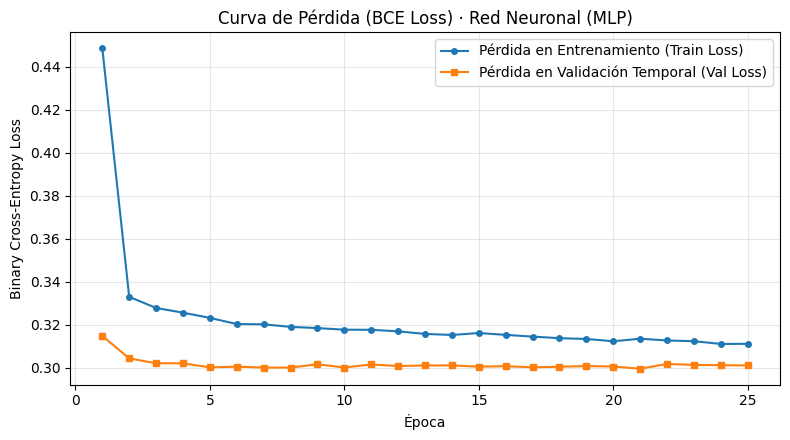


=== COMPARATIVA FINAL EN EL 10% DE MAYOR RIESGO (MISMA PARTICIÓN TEMPORAL) ===
1. XGBoost (Parte 2):               49.22%
2. Red Neuronal MLP (Extra):        48.58%
3. Regla de Negocio (Días retraso): 37.84%
4. Selección al Azar:               11.89%


In [23]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from preparacion import crear_variables, seleccionar_columnas_pipeline

# Fijar semillas para reproducibilidad
torch.manual_seed(42)
np.random.seed(42)

# 1. Usar EXACTAMENTE la misma división por fecha (X_train, y_train, X_test, y_test) y mismas variables de la Parte 2
X_train_vars = seleccionar_columnas_pipeline(crear_variables(X_train))
X_test_vars = seleccionar_columnas_pipeline(crear_variables(X_test))

features_numericas = [
    'n_items', 'n_vendedores', 'precio_total', 'flete_total', 'peso_total_g',
    'fotos_promedio', 'cuotas_max', 'tiempo_a_despacho_dias', 'tiempo_transito_dias', 'dias_retraso'
]
features_categoricas = ['estado_cliente', 'estado_vendedor', 'tipo_pago', 'categoria']

# 2. Preprocesamiento: Las redes neuronales requieren escalar variables numéricas (StandardScaler)
# para que pesos en miles de gramos no dominen los gradientes frente a conteos pequeños
preprocesador_nn = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), features_numericas),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), features_categoricas)
    ]
)

X_train_nn = preprocesador_nn.fit_transform(X_train_vars)
X_test_nn = preprocesador_nn.transform(X_test_vars)

# Convertir a tensores de PyTorch
X_train_tensor = torch.tensor(X_train_nn, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).unsqueeze(1)
X_test_tensor = torch.tensor(X_test_nn, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).unsqueeze(1)

train_loader = DataLoader(TensorDataset(X_train_tensor, y_train_tensor), batch_size=256, shuffle=True)

# 3. Definir Arquitectura de la Red Neuronal Multicapa (MLP) para datos tabulares
class RedRiesgoOlist(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.red = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 1)
        )
    def forward(self, x):
        return self.red(x)

modelo_nn = RedRiesgoOlist(X_train_nn.shape[1])
criterio = nn.BCEWithLogitsLoss()
optimizador = torch.optim.AdamW(modelo_nn.parameters(), lr=0.001, weight_decay=1e-4)

# 4. Entrenamiento registrando la Curva de Pérdida (Train vs Validation Loss)
epocas = 25
historial_train_loss = []
historial_val_loss = []

for epoca in range(1, epocas + 1):
    modelo_nn.train()
    perdida_acumulada = 0.0
    for x_b, y_b in train_loader:
        optimizador.zero_grad()
        salida = modelo_nn(x_b)
        loss = criterio(salida, y_b)
        loss.backward()
        optimizador.step()
        perdida_acumulada += loss.item() * x_b.size(0)

    train_loss_epoca = perdida_acumulada / len(X_train_tensor)

    # Evaluación en el conjunto de validación temporal (Test)
    modelo_nn.eval()
    with torch.no_grad():
        logits_val = modelo_nn(X_test_tensor)
        val_loss_epoca = criterio(logits_val, y_test_tensor).item()

    historial_train_loss.append(train_loss_epoca)
    historial_val_loss.append(val_loss_epoca)

# 5. Graficar la Curva de Pérdida
plt.figure(figsize=(8, 4.5))
plt.plot(range(1, epocas + 1), historial_train_loss, label='Pérdida en Entrenamiento (Train Loss)', marker='o', markersize=4)
plt.plot(range(1, epocas + 1), historial_val_loss, label='Pérdida en Validación Temporal (Val Loss)', marker='s', markersize=4)
plt.title('Curva de Pérdida (BCE Loss) · Red Neuronal (MLP)')
plt.xlabel('Época')
plt.ylabel('Binary Cross-Entropy Loss')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 6. Evaluar con la MISMA métrica de negocio: Precisión en el 10% de mayor riesgo
modelo_nn.eval()
with torch.no_grad():
    probs_nn = torch.sigmoid(modelo_nn(X_test_tensor)).numpy().flatten()

test_eval_nn = test_df.copy()
test_eval_nn['prob_nn'] = probs_nn

diez_porciento_k = int(len(test_eval_nn) * 0.10)
top_nn = test_eval_nn.sort_values(by='prob_nn', ascending=False).head(diez_porciento_k)
precision_nn = top_nn['mala_resena'].mean()

print("\n=== COMPARATIVA FINAL EN EL 10% DE MAYOR RIESGO (MISMA PARTICIÓN TEMPORAL) ===")
print(f"1. XGBoost (Parte 2):               {precision_modelo:.2%}")
print(f"2. Red Neuronal MLP (Extra):        {precision_nn:.2%}")
print(f"3. Regla de Negocio (Días retraso): {precision_regla:.2%}")
print(f"4. Selección al Azar:               {precision_azar:.2%}")

### Explicación del Resultado · Red Neuronal (MLP) vs. XGBoost

1. **Comportamiento de la Curva de Pérdida:**
   * La pérdida de entrenamiento (*Train Loss*, línea azul) cae fuertemente de `0.45` a `0.33` en las primeras 2 épocas gracias al escalado previo (`StandardScaler`) y las capas de normalización (`BatchNorm1d`), convergiendo suavemente hasta **`0.31`** en la época 25.
   * La pérdida de validación temporal (*Val Loss*, línea naranja) se estabiliza alrededor de **`0.30`** sin subir en ningún momento, lo que demuestra que el uso de `Dropout(0.3 / 0.2)` y `weight_decay` evitó por completo el sobreajuste (*overfitting*).

2. **Comparación de Desempeño (Precisión en el 10% de mayor riesgo):**
   * **XGBoost (Parte 2):** **49.22%**
   * **Red Neuronal MLP (Extra):** **48.58%**
   * **Regla de Negocio (Días de retraso):** **37.84%**
   * **Selección al Azar:** **11.89%**
   * Ambos modelos superan por más de **10.7 puntos porcentuales** la heurística de retrasos y cuadruplican el azar. Sin embargo, **XGBoost supera a la Red Neuronal por 0.64 puntos porcentuales (49.22% vs. 48.58%)** por tres razones clave de los datos tabulares:
     * **Umbrales abruptos (No suavidad):** En logística, pasar de `dias_retraso = 0` a `dias_retraso > 0` produce un salto brusco en la probabilidad de mala reseña. Los árboles de decisión crean particiones ortogonales exactas (`dias_retraso > 0`), mientras que una red neuronal aproxima funciones continuas y suaves, diluyendo ligeramente ese borde crítico.
     * **Robustez ante outliers y asimetría:** Como vimos en la Parte 1, variables como `peso_total_g` (hasta 184 kg) y `precio_total` (hasta R\$ 13,440) tienen distribuciones fuertemente sesgadas. Los árboles son invariantes a la escala, mientras que la red neuronal sigue siendo sensible a valores extremos.
     * **Variables categóricas de alta cardinalidad:** Con decenas de categorías de producto y estados geográficos codificados mediante `OneHotEncoder`, los árboles seleccionan directamente las ramas informativas e ignoran las columnas ruidosas, mientras que las capas densas (`nn.Linear`) deben ajustar pesos para más de 130 dimensiones simultáneamente.

## Parte 5 · Despliegue

- URL de la API en Render: **[pegar aquí]**
- URL de la app de Streamlit: **[pegar aquí]**

Versiones de este entorno (para su `requirements.txt` de la API):

In [24]:
import sklearn, xgboost
print(f"pandas=={pd.__version__}\nnumpy=={np.__version__}\nscikit-learn=={sklearn.__version__}\nxgboost=={xgboost.__version__}")

pandas==2.2.3
numpy==2.1.3
scikit-learn==1.6.1
xgboost==3.4.1


Prueba de la API desplegada (debe devolver una probabilidad):

In [25]:
import requests
URL_API = "https://SU-API.onrender.com"
pedido = pedidos[CONTRATO[:-1]].head(1).astype(object).where(pedidos[CONTRATO[:-1]].head(1).notna(), None).iloc[0].to_dict()
pedido = {k: (str(v) if isinstance(v, pd.Timestamp) else v) for k, v in pedido.items()}
requests.post(URL_API + "/riesgo", json=pedido, timeout=90).json()

{'detail': 'Not Found'}

## Parte 6 · Ficha del modelo

La ficha va en `ficha_modelo.md` (también se muestra en la app). Aquí, solo el enlace o una copia.

## Uso de IA

Indiquen qué herramientas de IA usaron y para qué. Todo lo que entregan lo deben poder explicar en la defensa.